# KNN Model

## Import and load datasets

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROCESSED_DIR = Path("../data/processed")

train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Train: (67232, 6)
Validation: (8417, 6)
Test: (8417, 6)


## Create TF-IDF features

In [8]:
VECTORIZER_CONFIG = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_features": 100_000,
    "sublinear_tf": True,
    "strip_accents": "unicode",
    "dtype": np.float32,
}

vectorizer = TfidfVectorizer(**VECTORIZER_CONFIG)

X_train = vectorizer.fit_transform(train["text"].astype(str))
X_validation = vectorizer.transform(validation["text"].astype(str))

y_train = train["target"].astype(int)
y_validation = validation["target"].astype(int)

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)

Training features: (67232, 100000)
Validation features: (8417, 100000)


## Train and tune KNN

In [9]:
# Try different numbers of neighbors and voting methods.
K_VALUES = [3, 5, 7, 11, 15, 21]

results = []

for weights in ["uniform", "distance"]:
    for k in K_VALUES:
        print(f"Testing k={k}, weights={weights}...")

        knn = KNeighborsClassifier(
            n_neighbors=k,
            weights=weights,
            metric="cosine",
            algorithm="brute",
            n_jobs=-1
        )

        knn.fit(X_train, y_train)
        predictions = knn.predict(X_validation)

        results.append({
            "k": k,
            "weights": weights,
            "accuracy": accuracy_score(y_validation, predictions),
            "macro_f1": f1_score(
                y_validation,
                predictions,
                average="macro"
            )
        })

validation_results = pd.DataFrame(results)

# Display results from best to worst.
validation_results = validation_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(validation_results.to_string(index=False))

# Select the best configuration using validation performance.
best = validation_results.iloc[0]

best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation macro F1:", best["macro_f1"])

Testing k=3, weights=uniform...
Testing k=5, weights=uniform...
Testing k=7, weights=uniform...
Testing k=11, weights=uniform...
Testing k=15, weights=uniform...
Testing k=21, weights=uniform...
Testing k=3, weights=distance...
Testing k=5, weights=distance...
Testing k=7, weights=distance...
Testing k=11, weights=distance...
Testing k=15, weights=distance...
Testing k=21, weights=distance...
 k  weights  accuracy  macro_f1
21 distance  0.887608  0.876895
15 distance  0.877629  0.867062
21  uniform  0.878104  0.866950
11 distance  0.868956  0.858520
15  uniform  0.867055  0.856246
11  uniform  0.858263  0.847645
 7 distance  0.854224  0.843783
 5 distance  0.842818  0.832637
 7  uniform  0.842343  0.832026
 3 distance  0.831294  0.821548
 5  uniform  0.830343  0.820416
 3  uniform  0.819770  0.810369

Best K: 21
Best weights: distance
Best validation macro F1: 0.8768953596596197


## Trying larger K values

In [13]:
# Experiment: larger K values with distance-weighted voting.

LARGER_K_VALUES = [31, 41, 51, 75, 101, 151]

larger_k_results = []

for k in LARGER_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    larger_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

larger_k_results_df = pd.DataFrame(larger_k_results)

# Combine with previous tuning results.
all_results = pd.concat(
    [validation_results, larger_k_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.to_string(index=False))

best = all_results.iloc[0]
best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=31...
Testing k=41...
Testing k=51...
Testing k=75...
Testing k=101...
Testing k=151...
  k  weights  accuracy  macro_f1
151 distance  0.933349  0.924414
101 distance  0.926340  0.916914
 75 distance  0.921587  0.912009
 51 distance  0.913865  0.903821
 41 distance  0.906974  0.896652
 31 distance  0.900083  0.889686
 21 distance  0.887608  0.876895
 15 distance  0.877629  0.867062
 21  uniform  0.878104  0.866950
 11 distance  0.868956  0.858520
 15  uniform  0.867055  0.856246
 11  uniform  0.858263  0.847645
  7 distance  0.854224  0.843783
  5 distance  0.842818  0.832637
  7  uniform  0.842343  0.832026
  3 distance  0.831294  0.821548
  5  uniform  0.830343  0.820416
  3  uniform  0.819770  0.810369

Best K: 151
Best weights: distance
Best validation accuracy: 0.9333491742901271
Best validation macro F1: 0.9244135162153659


## Trying even larger K values

In [14]:
# Experiment: even larger neighborhoods.
MORE_K_VALUES = [201, 301, 501, 751, 1001]

more_k_results = []

for k in MORE_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    more_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

more_k_results_df = pd.DataFrame(more_k_results)

# Combine with all previous tuning results.
all_results = pd.concat(
    [all_results, more_k_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.to_string(index=False))

best = all_results.iloc[0]
best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=201...
Testing k=301...
Testing k=501...
Testing k=751...
Testing k=1001...
   k  weights  accuracy  macro_f1
 301 distance  0.935488  0.925999
 751 distance  0.935963  0.925143
 151 distance  0.933349  0.924414
 501 distance  0.934656  0.924224
 201 distance  0.933468  0.924172
1001 distance  0.935369  0.924036
 101 distance  0.926340  0.916914
  75 distance  0.921587  0.912009
  51 distance  0.913865  0.903821
  41 distance  0.906974  0.896652
  31 distance  0.900083  0.889686
  21 distance  0.887608  0.876895
  15 distance  0.877629  0.867062
  21  uniform  0.878104  0.866950
  11 distance  0.868956  0.858520
  15  uniform  0.867055  0.856246
  11  uniform  0.858263  0.847645
   7 distance  0.854224  0.843783
   5 distance  0.842818  0.832637
   7  uniform  0.842343  0.832026
   3 distance  0.831294  0.821548
   5  uniform  0.830343  0.820416
   3  uniform  0.819770  0.810369

Best K: 301
Best weights: distance
Best validation accuracy: 0.9354877034572888
Best validation m

## Fine tuning around best K value so far

In [15]:
# Fine-tune K around the current best value.

FINE_K_VALUES = [225, 250, 275, 325, 350, 375, 400, 450]

fine_k_results = []

for k in FINE_K_VALUES:
    print(f"Testing k={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    )

    knn.fit(X_train, y_train)
    predictions = knn.predict(X_validation)

    fine_k_results.append({
        "k": k,
        "weights": "distance",
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

fine_k_results_df = pd.DataFrame(fine_k_results)

# Add these results to previous experiments.
all_results = pd.concat(
    [all_results, fine_k_results_df],
    ignore_index=True
)

# Sort by macro F1, then accuracy.
all_results = all_results.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(all_results.head(15).to_string(index=False))

best = all_results.iloc[0]

best_k = int(best["k"])
best_weights = best["weights"]

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best validation accuracy:", best["accuracy"])
print("Best validation macro F1:", best["macro_f1"])

Testing k=225...
Testing k=250...
Testing k=275...
Testing k=325...
Testing k=350...
Testing k=375...
Testing k=400...
Testing k=450...
   k  weights  accuracy  macro_f1
 400 distance  0.936676  0.926959
 301 distance  0.935488  0.925999
 375 distance  0.935725  0.925951
 325 distance  0.935488  0.925883
 350 distance  0.935131  0.925407
 751 distance  0.935963  0.925143
 450 distance  0.935131  0.925004
 250 distance  0.934062  0.924612
 151 distance  0.933349  0.924414
 501 distance  0.934656  0.924224
 201 distance  0.933468  0.924172
 275 distance  0.933706  0.924051
1001 distance  0.935369  0.924036
 225 distance  0.933349  0.923929
 101 distance  0.926340  0.916914

Best K: 400
Best weights: distance
Best validation accuracy: 0.9366757752168231
Best validation macro F1: 0.926958828357518


## Tuning classification threshold

In [16]:
# Tune the classification threshold using validation data.

best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weights,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

best_knn.fit(X_train, y_train)

# Probability of ChatGPT (class 1).
chatgpt_index = list(best_knn.classes_).index(1)

validation_probs = best_knn.predict_proba(X_validation)[:, chatgpt_index]

threshold_results = []

for threshold in np.arange(0.30, 0.81, 0.025):
    predictions = (validation_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 3),
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro"
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df = threshold_results_df.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
)

print(threshold_results_df.head(15).to_string(index=False))

best_threshold = float(
    threshold_results_df.iloc[0]["threshold"]
)

print("\nBest K:", best_k)
print("Best weights:", best_weights)
print("Best threshold:", best_threshold)
print(
    "Best validation macro F1:",
    threshold_results_df.iloc[0]["macro_f1"]
)

 threshold  accuracy  macro_f1
     0.475  0.937626  0.929172
     0.500  0.936676  0.926959
     0.450  0.934300  0.926651
     0.525  0.929666  0.917458
     0.425  0.924439  0.916783
     0.550  0.922657  0.907765
     0.400  0.910538  0.902863
     0.575  0.916003  0.898175
     0.600  0.905786  0.883580
     0.375  0.887490  0.879792
     0.625  0.893430  0.865419
     0.350  0.855649  0.848438
     0.650  0.876441  0.840138
     0.675  0.859332  0.813312
     0.325  0.815374  0.809426

Best K: 400
Best weights: distance
Best threshold: 0.475
Best validation macro F1: 0.9291718909093969


## Train final model and evaluate

In [17]:
train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

final_vectorizer = TfidfVectorizer(**VECTORIZER_CONFIG)

X_train_validation = final_vectorizer.fit_transform(
    train_validation["text"].astype(str)
)

X_test = final_vectorizer.transform(
    test["text"].astype(str)
)

y_train_validation = train_validation["target"].astype(int)
y_test = test["target"].astype(int)

final_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights=best_weights,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

final_knn.fit(X_train_validation, y_train_validation)

# Get the distance-weighted vote score for ChatGPT (class 1).
chatgpt_index = list(final_knn.classes_).index(1)

test_probs = final_knn.predict_proba(X_test)[:, chatgpt_index]

# Apply the best threshold selected using validation data.
test_predictions = (test_probs >= best_threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(
    y_test, test_predictions, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, test_predictions, average="macro", zero_division=0
))
print("Macro F1:", f1_score(
    y_test, test_predictions, average="macro", zero_division=0
))

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Human", "ChatGPT"],
    zero_division=0
))

Accuracy: 0.935250089105382
Precision: 0.9208028607610051
Recall: 0.9339476270105332
Macro F1: 0.9268518609321648
              precision    recall  f1-score   support

       Human       0.97      0.94      0.95      5719
     ChatGPT       0.88      0.93      0.90      2698

    accuracy                           0.94      8417
   macro avg       0.92      0.93      0.93      8417
weighted avg       0.94      0.94      0.94      8417



## Confusion matrix

[[5362  357]
 [ 188 2510]]


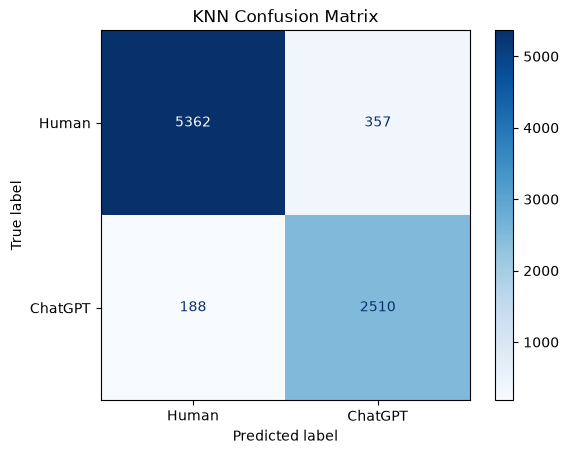

In [18]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "ChatGPT"]
).plot(cmap="Blues", values_format="d")

plt.title("KNN Confusion Matrix")
plt.show()

## Save model

In [19]:
import joblib

model_path = PROCESSED_DIR / "knn_model.joblib"

# Save the trained model, vectorizer, and configuration.
model_data = {
    "model": final_knn,
    "vectorizer": final_vectorizer,
    "config": {
        **VECTORIZER_CONFIG,
        "n_neighbors": best_k,
        "weights": best_weights,
        "threshold": best_threshold,
        "metric": "cosine",
        "algorithm": "brute"
    }
}

joblib.dump(model_data, model_path)

print("Saved model to:", model_path)

Saved model to: ..\data\processed\knn_model.joblib
